## Importo posibles librerías

In [2]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

## ANÁLISIS 7 - Crear un indicador global de rendimiento académico

Con esta medida podemos ver qué porcentaje de estudiantes se encuentra en cada nivel y qué características comparten los estudiantes con mejor rendimiento.

Esta medida también nos puede ayudar a identificar qué características aparecen con mayor frecuencia entre los estudiantes cuya nota media es inferior a 50, que podría ayudar a detectar colectivos que podrían necesitar mayor apoyo educativo.

In [3]:
sp = pd.read_csv("../data/StudentsPerformance_depurado.csv", sep =",")

Lo primero es crear una variable clasificatoria en base a la variable ya creada global_score en base a:

    Rendimiento	    Puntuación
    Bajo	            0-49,99
    Medio	            50-69,99
    Alto	            70-84,99
    Excelente	    85-100

In [4]:
sp["performance_level"] = pd.cut(sp["global_score"], bins=[0, 50, 70, 85, 100], labels=["low", "medium", "high", "excellent"], right=False)

sp["performance_level"].value_counts().sort_index()

perf = sp["performance_level"].value_counts(normalize=True).sort_index() * 100

perf.round(2)

performance_level
low          10.33
medium       43.93
high         34.40
excellent    11.33
Name: proportion, dtype: float64

Y ahora hacemos el gráfico de su distribución:

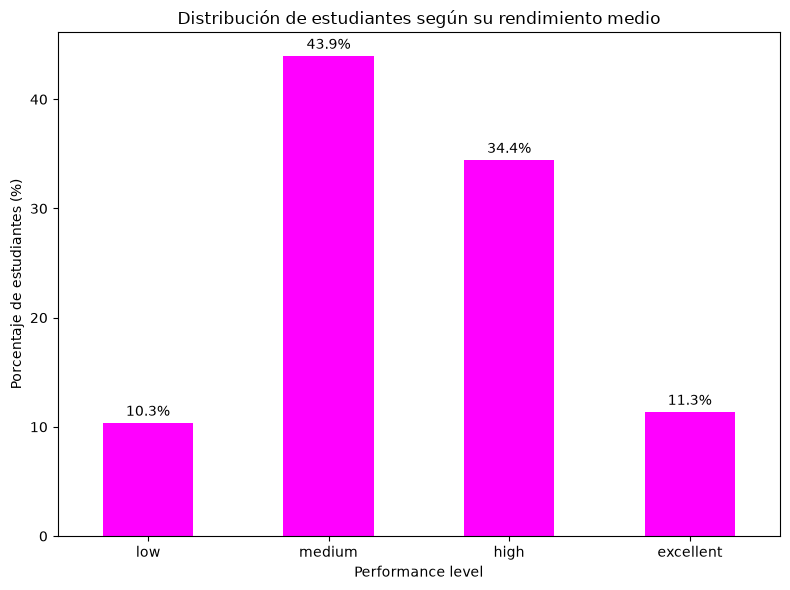

In [5]:
porcen = sp["performance_level"].value_counts(normalize=True).sort_index() * 100

perf = porcen.plot(kind="bar", color="magenta", figsize=(8, 6))

perf.bar_label(perf.containers[0], fmt="%.1f%%", padding=3)

plt.title("Distribución de estudiantes según su rendimiento medio")
plt.ylabel("Porcentaje de estudiantes (%)")
plt.xlabel("Performance level")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../img/Grafico_7_1.jpg", dpi=300, bbox_inches="tight")

plt.show()

A diferencia de los estudiantes que habíamos calculado en el inicio del estudio, en este caso, los que obtienen un bajo rendimiento son el 10.3% que de media global tienen una nota menor de 50 (sobre 100). Y por el contrario, el grupo de alto rendimiento son el 11.3% que tienen una nota superior a 85 (sobre 100).



Ahora, teniendo estos grupos definidos en la muestra, podemos ver qué contexto  mayoritario tienen los grupos de menor rendimiento y los de mayor rendimiento.

* Contexto del grupo de bajo rendimiento:

In [6]:
sp.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,global_score,performance_level
0,female,group B,bachelor's degree,standard,not completed,72,72,74,72.67,high
1,female,group C,some college,standard,completed,69,90,88,82.33,high
2,female,group B,master's degree,standard,not completed,90,95,93,92.67,excellent
3,male,group A,associate's degree,free/reduced,not completed,47,57,44,49.33,low
4,male,group C,some college,standard,not completed,76,78,75,76.33,high


In [7]:
gender_bajorend = sp["gender"][sp["performance_level"] == "low"].mode().unique()
race_bajorend = sp["race_ethnicity"][sp["performance_level"] == "low"].mode().unique()
parental_bajorend = sp["parental_level_of_education"][sp["performance_level"] == "low"].mode().unique()
lunch_bajorend = sp["lunch"][sp["performance_level"] == "low"].mode().unique()
test_bajorend = sp["test_preparation_course"][sp["performance_level"] == "low"].mode().unique()

print("Las características mayoritarias del grupo de bajo rendimiento son: ")
print("")
print("Gender: ", gender_bajorend.value_counts())
print("----------------------")
print("Race/Ethnicity: ", race_bajorend.value_counts())
print("----------------------")
print("Parental level of Education: ", parental_bajorend.value_counts())
print("----------------------")
print("School Lunch Program: ", lunch_bajorend.value_counts())
print("----------------------")
print("Test Preparation Course: ", test_bajorend.value_counts())

Las características mayoritarias del grupo de bajo rendimiento son: 

Gender:  male    1
Name: count, dtype: int64
----------------------
Race/Ethnicity:  group C    1
Name: count, dtype: int64
----------------------
Parental level of Education:  high school    1
Name: count, dtype: int64
----------------------
School Lunch Program:  free/reduced    1
Name: count, dtype: int64
----------------------
Test Preparation Course:  not completed    1
Name: count, dtype: int64


* Contexto del grupo de alto rendimiento:

In [9]:
gender_altorend = sp["gender"][sp["performance_level"] == "excellent"].mode().unique()
race_altorend = sp["race_ethnicity"][sp["performance_level"] == "excellent"].mode()
parental_altorend = sp["parental_level_of_education"][sp["performance_level"] == "excellent"].mode().unique()
lunch_altorend = sp["lunch"][sp["performance_level"] == "excellent"].mode().unique()
test_altorend = sp["test_preparation_course"][sp["performance_level"] == "excellent"].mode().unique()

print("Las características mayoritarias del grupo de alto rendimiento son: ")
print("")
print("Gender: ", gender_altorend.value_counts())
print("----------------------")
print("Race/Ethnicity: ", race_altorend.value_counts())
print("----------------------")
print("Parental level of Education: ", parental_altorend.value_counts())
print("----------------------")
print("School Lunch Program: ", lunch_altorend.value_counts())
print("----------------------")
print("Test Preparation Course: ", test_altorend.value_counts())

Las características mayoritarias del grupo de alto rendimiento son: 

Gender:  female    1
Name: count, dtype: int64
----------------------
Race/Ethnicity:  race_ethnicity
group C    1
Name: count, dtype: int64
----------------------
Parental level of Education:  associate's degree    1
Name: count, dtype: int64
----------------------
School Lunch Program:  standard    1
Name: count, dtype: int64
----------------------
Test Preparation Course:  completed    1
Name: count, dtype: int64
